In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import dataclasses
import pickle
import os

Mounted at /content/drive


In [ ]:
import sys, os

GIT_USER  = "JoeyTurn"
GIT_REPO  = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)


Cloning into 'kernel_ICL'...
remote: Enumerating objects: 726, done.
remote: Counting objects: 100% (261/261), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 726 (delta 179), reused 164 (delta 85), pack-reused 465 (from 1)
Receiving objects: 100% (726/726), 43.46 MiB | 19.41 MiB/s, done.
Resolving deltas: 100% (373/373), done.
Cloning into 'modelscape'...
remote: Enumerating objects: 234, done.
remote: Counting objects: 100% (234/234), done.
remote: Compressing objects: 100% (156/156), done.
remote: Total 234 (delta 142), reused 168 (delta 76), pack-reused 0 (from 0)
Receiving objects: 100% (234/234), 218.78 KiB | 12.87 MiB/s, done.
Resolving deltas: 100% (142/142), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 8.05 MiB/s, do

In [ ]:
sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

In [ ]:
%matplotlib inline
import math
import os

import numpy as np
import torch
import matplotlib.pyplot as plt
import copy

from kernels_can_icl.kernel_theory_multidim import generate_multidim_kicl_monomials
from kernels_can_icl.kernel_eigsys import eigendecompose, kernel_matrix, phi1_x_query, phi2_y_X_x_query
from kernels_can_icl.eigenlearning import compute_learnabilities, learning_curve, learning_curve_OOD_diag#, learning_curve_OOD
from kernels_can_icl.task_distrs import RegressionTaskDistribution
from kernels_can_icl.level_coefficients import *
from kernels_can_icl.utils import estimate_max_n, seed_everything, ensure_torch, ensure_numpy
from kernels_can_icl.kernels import PolynomialKernel, GaussianKernel, LaplaceKernel, ReluNTK
from kernels_can_icl.monomial import Monomial

In [ ]:
def make_antipodal_pretrain_W(T, d, sigma_beta, device):
	"""

	Build a pretrain_W of shape (T, d) whose rows sum to zero (mean = 0 exactly).

	For even T: interleave each base sample with its negation.
		pretrain_W[2j] = base[j],  pretrain_W[2j+1] = -base[j]  for j in 0..T//2-1
	For odd T: same for T-1 rows, then append a zero vector.
	"""
	half = T // 2
	base = torch.normal(mean=0.0, std=sigma_beta, size=(half, d), device=device)
	# base = torch.tensor(1.0, device=device).repeat(half, d) * sigma_beta
	paired = torch.stack([base, -base], dim=1).reshape(half * 2, d)
	if T % 2 == 0:
		return paired
	else:
		return torch.cat([paired, torch.zeros(1, d, device=device)], dim=0)


In [ ]:
folder_path = '/content/drive/My Drive/picl/results/kernels/'
file_path = os.path.join(folder_path, 'gaussiankernel_T1.pkl')
config = {
    "seed": 33,
    "dim": 5,#1,
    "L": 8,#7,
    "distribution": "pretrain",
    "T": 1,
    "sigma_sq": 0.1,
    "draw_betas": "normal",
    "beta_sd": 1.0,
    "trials": 20,
    "kernel_class": "GaussianKernel",
    "kernel_params": {
        "ridge": 0.01,#1,
        "kernel_width": 3,
        "max_degree": 3,
        # "coeffs": [1.0, 0.04],
        "coeffs": [1.0, 0.111, 0.00617283951, 0.000228623685],
        # "coeffs": [1.0, 0.04, 0.0016, 0.000064],
        # "coeffs": [1.0, 0.04, 0.0016, 0.000064, 0.00000256, 1.024e-7],
        # "coeffs": [1.0, 0.04, 0.0016, 0.000064, 0.00000256, 1.024e-7, 4.096e-9, 1.6384e-10],
        # "coeffs": [1.0, 0.00, 0.0016, 0.0, 0.00000256, 1.024e-7, 4.096e-9],
    },
    "n": 14000,#20000,#25600,#30000,
    "ns": [10, 20, 40, 80, 100, 200, 500, 700, 1000, 2000, 3000, 5000, 10000, 20000, 25000],
    "min_n": 2,
    "max_n": 30000,
    "memory_safety": 0.2,
    "matrix_factor": 3.0,
    "max_retries": 10,
    "retry_shrink": 0.96,
    "n_test": 2048,
    "expt_dir": "kernel_ICL/ICLE",
    "base_name": "eigenstructure_validation_T1",
    "antipodal": False,
}
test_config = copy.deepcopy(config)
test_config.update({"distribution": "true"})
test_config.update({"T": 1})

In [ ]:
def generate_data(task_distr: RegressionTaskDistribution, batch_sz, gen=None, distribution=None):
	dist = config["distribution"] if distribution is None else distribution
	X_ctx, y_ctx, X_q, y_q = task_distr.generate_data(
		context_len=int(config["L"]), batch_sz=int(batch_sz),
		distribution=dist, uniform_beta_sampling=True,
		# norm_X=True,
		# gen=gen
	)
	X = task_distr._get_input(X_ctx, y_ctx, X_q)
	#normalization
	W = task_distr.pretrain_W.detach()

	# E[beta^2] is the mean of the squared weights across the task distribution
	# mu_2 = (W ** 2).mean()
	mu_2 = ensure_torch(task_distr.sigma_beta2) if dist == "true" else (W ** 2).mean()

	# E[y^2] = E[beta^2]*sigma_q^2 + sigma^2
	expected_power = mu_2* task_distr.d * task_distr.sigma_q2 + task_distr.sigma**2

	y_0 = y_q.squeeze(-1).squeeze(-1) / torch.sqrt(expected_power)
	# print(f'X power (Mean squared): {(X ** 2).mean().item():.4f}')
	# print(f'Y power (Mean squared): {(y_0 ** 2).mean().item():.4f}')
	return X, y_0

def generate_task_distr(config, gen=None):
	task_distr = RegressionTaskDistribution(
		dim=int(config["dim"]), num_weights=int(config["T"]),
		noise_variance=float(config["sigma_sq"]), sample_beta=str(config["draw_betas"]),
		sigma_beta2=float(config["beta_sd"]) ** 2, gram_wanted=False,
		context_len=int(config["L"]), gen=gen
	)
	if config["antipodal"]:
		task_distr.pretrain_W = make_antipodal_pretrain_W(
			task_distr.T, task_distr.d, task_distr.sigma_beta, task_distr.device
		)
	# task_distr.pretrain_W = task_distr.pretrain_W + 0.6
	# task_distr.pretrain_W = ensure_torch(np.array([0.0615, 0.4, 1.2, 1.5385]).reshape(2 * 2, 1))

	return task_distr

def run_once(task_distr, n: int, L = config["L"], gen=None, test_distr=None):
	X_flat, y_vec = generate_data(task_distr, batch_sz=n, gen=gen)

	X_flat = ensure_torch(X_flat)
	y_vec = ensure_torch(y_vec).T

	# --- KRR predictor ---
	_KRR_MAP = {
		"PolynomialKernel": PolynomialKernel,
		"GaussianKernel":   GaussianKernel,
		"LaplaceKernel":    LaplaceKernel,
		"ReluNTK":          ReluNTK,
	}
	krr = _KRR_MAP[config["kernel_class"]](**dict(config["kernel_params"]))
	krr.fit(X_flat, y_vec)
	# print(f"KRR fitted")

	n_test = config.get("n_test", 2048)
	X_flat_test, y_vec_test = generate_data(task_distr, batch_sz=n_test)
	X_flat_test = ensure_torch(X_flat_test)
	y_vec_test  = ensure_torch(y_vec_test).T
	y_pred = krr.predict(X_flat_test).squeeze(-1)
	krr_test_mse = torch.nn.functional.mse_loss(y_pred, y_vec_test).item()
	#OOD
	if test_distr is not None:
		X_test, y_test = generate_data(test_distr, batch_sz=n_test, gen=gen, distribution="true")
		X_test = ensure_torch(X_test)
		y_test = ensure_torch(y_test).T
		y_pred_test = krr.predict(X_test).squeeze(-1)
		krr_test_ood_mse = torch.nn.functional.mse_loss(y_pred_test, y_test).item()
	else:
		krr_test_ood_mse = krr_test_mse
	# print(f"KRR test MSE: {krr_test_mse:.6f}")

	return krr_test_mse, krr_test_ood_mse

In [ ]:
#empirical
gen, rng = seed_everything(config["seed"], device_id=1)
task_distr = generate_task_distr(config, gen=gen)
test_distr = generate_task_distr(test_config, gen=gen)

max_n = estimate_max_n(config=config, n=config.get("n"))
retries = int(config["max_retries"])
shrink = float(config["retry_shrink"])
last_err = None

emp_test_errors = np.zeros((config["trials"], len(config["ns"])))
emp_ood_errors = np.zeros((config["trials"], len(config["ns"])))

for trial_key in range(config["trials"]):
	for n in config["ns"]:
		gen, rng = seed_everything(config["seed"], device_id=trial_key)
		krrtestmse, krrtestoodmse = run_once(task_distr, n=n, gen=gen, test_distr=test_distr)
		emp_test_errors[trial_key, config["ns"].index(n)] = krrtestmse
		emp_ood_errors[trial_key, config["ns"].index(n)] = krrtestoodmse

/tmp/ipykernel_400/2685611381.py:45: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4480.)
  y_vec = ensure_torch(y_vec).T


In [ ]:
def solve_gs_block(C, V):
    C = np.atleast_2d(np.asarray(C, dtype=float)); V = np.asarray(V, dtype=float).ravel()
    try: Lc = np.linalg.cholesky(C)
    except np.linalg.LinAlgError: Lc = np.linalg.cholesky(C + 1e-12*np.eye(C.shape[0]))
    return np.linalg.solve(Lc, V)

def build_eigcoeffs_expanded(impt_list, betas, sigma_sq, L_config, sigma_x2):
    betas = ensure_numpy(betas); betas_arr = np.asarray(betas, dtype=float)
    if betas_arr.ndim == 2: d = int(betas_arr.shape[1])
    elif betas_arr.ndim == 1: d = 1; betas_arr = betas_arr.reshape(-1, 1)
    else: raise ValueError("betas must be 1D or 2D")
    epsilon2 = float(sigma_sq); L = float(L_config - 1); v = float(sigma_x2)

    N2 = np.sum(betas_arr**2, axis=1)
    M_N = np.mean(N2); M_N2 = np.mean(N2**2)
    Mb  = np.mean(betas_arr, axis=0)                       # (d,)   E[b_a]
    Mbb = (betas_arr.T @ betas_arr) / betas_arr.shape[0]   # (d,d)  E[b_a b_b]
    MbN = np.mean(betas_arr * N2[:, None], axis=0)         # (d,)   E[b_a ||b||^2]

    norm_y = np.sqrt(max(M_N * v + epsilon2, 1e-12))
    coeffs_map = {}

    for k in range(d):                                     # k = query axis (the X_q[k] factor)
        # ---------- DEGREE 1 ----------
        coeffs_map[f"q{k}"] = solve_gs_block([[v]], [Mb[k] * v])[0]

        # ---------- DEGREE 3 ----------  block = [y2q{k}, X0yq{k}, ..., X_{d-1}yq{k}]
        # V_i = <y*, feature_i orthogonalized against q{k}>   (epsilon^2 cancels in this projection)
        V = np.empty(1 + d)
        V[0] = L * v**2 * (MbN[k] - Mb[k] * M_N)                       # y2q{k}
        V[1:] = L * v**2 * (Mbb[:, k] - Mb * Mb[k])                    # X{a}yq{k} = L v^2 Cov(b_a,b_k)

        # C = block Gram, Schur-complemented against q{k}
        C = np.empty((1 + d, 1 + d))
        C[0, 0] = v**3 * L * ((L + 2) * M_N2 - L * M_N**2) \
                  + 4 * L * v**2 * epsilon2 * M_N + 2 * L * v * epsilon2**2     # == your C00
        C0a = L * (L + 2) * v**2 * (v * MbN + epsilon2 * Mb) \
              - L**2 * v**2 * (M_N * v + epsilon2) * Mb                          # generalizes C01
        C[0, 1:] = C0a; C[1:, 0] = C0a
        Caa = L * (L + 1) * v**3 * Mbb - L**2 * v**3 * np.outer(Mb, Mb)          # generalizes C11
        Caa[np.diag_indices(d)] += L * v**3 * M_N + L * v**2 * epsilon2
        C[1:, 1:] = Caa

        c = solve_gs_block(C, V)
        coeffs_map[f"y2q{k}"] = c[0]
        for a in range(d):
            coeffs_map[f"X{a}yq{k}"] = c[1 + a]
        coeffs_map[f"Xyq{k}"] = c[1 + k]      # diagonal alias (your old name)

    eigcoeffs = np.zeros(len(impt_list))
    for i, name in enumerate(impt_list):
        eigcoeffs[i] = coeffs_map.get(name, 0.0) / norm_y
    return eigcoeffs


# ── test: mu_k = 1 for all k ──────────────────────────────────────────────────
if __name__ == "__main__":
    betas_ones = np.ones(100)
    impt_list_test = ["q0", "y2q0", "Xyq0", "other_monomial"]
    ec = build_eigcoeffs_expanded(impt_list_test, betas_ones,
                            sigma_sq=0.0, L_config=5, sigma_x2=1.0)
    print("eigcoeffs:", ec)
    # Expected: [1.0, ~0, ~0, 0]
    assert np.isclose(ec[0], 1.0), f"q0 should be 1, got {ec[0]}"
    assert np.isclose(ec[1], 0.0, atol=1e-10), f"y2q0 should be 0, got {ec[1]}"
    assert np.isclose(ec[2], 0.0, atol=1e-10), f"Xyq0 should be 0, got {ec[2]}"
    print("Test passed ✓")

    betas_anti = np.array([1, -1] * 40)
    impt_list_test = ["q0", "y2q0", "Xyq0", "other_monomial"]
    L = 7
    ec_anti = build_eigcoeffs_expanded(impt_list_test, betas_anti,
                            sigma_sq=0.0, L_config=L, sigma_x2=1.0)
    print("eigcoeffs:", ec_anti)
    # Expected: [1.0, ~0, ~0, 0]
    print((L/(L+2))**(0.5))
    print(np.mean(betas_anti**2.))
    # assert np.isclose(ec_anti[0], 1.0), f"q0 should be 1, got {ec_anti[0]}"
    # assert np.isclose(ec_anti[1], 0.0, atol=1e-10), f"y2q0 should be 0, got {ec_anti[1]}"
    # assert np.isclose(ec_anti[2], L/(L+2), rtol=1e-1), f"Xyq0 should be L/(L+2) ({L/(L+2)}), got {ec_anti[2]}"
    # print(ec_anti[2]**(-0.5))
    print("Test passed ✓")

eigcoeffs: [1. 0. 0. 0.]
Test passed ✓
eigcoeffs: [0.        0.        0.8660254 0.       ]
0.8819171036881969
1.0
Test passed ✓


In [ ]:
"""
Self-contained degree-<=3 OOD Gram.  No external module dependencies.

test_gram_OOD_gaussian(betas_train, sb2, v, e, L, d, marked) -> (S, eigvals)
    S_ij = <phi_i, phi_j>_q for an isotropic-Gaussian test task prior beta_q ~ N(0, sb2 I),
    with phi = the train-prior eigenfunctions (train Gram diagonalized on the marked block).
    eigvals are the matching kernel eigenvalues for compute_learnabilities.

The train Gram is averaged empirically over betas_train (your discrete pretraining tasks); the
test Gram is the exact population value under N(0,sb2 I), via Isserlis on the task prior.

Marked-mode labels (degree<=3):  q{b}, y2q{b}, X{a}yq{b}, X{a}X{ap}q{b}  (0 <= a <= ap < d).
"""
import numpy as np, math, itertools

# ---- beta-polynomial algebra:  poly = {multi-index k (len d) -> coef} ----
def _df(n):
    r = 1.0
    while n > 0: r *= n; n -= 2
    return r
def _gm(p, sb2):                                   # E[Z^p], Z ~ N(0, sb2)
    return 0.0 if p % 2 else _df(p - 1) * sb2 ** (p // 2)

def _tok_poly(px, py, v, e, d):
    """{k: coef} for E_{X,noise}[ prod X[a]^px[a] y^py | beta ] = sum_k coef * prod beta_c^{k_c}."""
    def momX(p): return 0.0 if p % 2 else _df(p - 1) * v ** (p // 2)
    def comps(m, dd):
        if dd == 1: yield (m,); return
        for i in range(m + 1):
            for rest in comps(m - i, dd - 1): yield (i,) + rest
    poly = {}
    for j in range(py + 1):
        Exi = 0.0 if j % 2 else _df(j - 1) * e ** (j // 2)
        if Exi == 0.0: continue
        cj = math.comb(py, j); m = py - j
        for k in comps(m, d):
            mult = math.factorial(m)
            for kc in k: mult //= math.factorial(kc)
            xm = 1.0
            for a in range(d):
                xm *= momX(px[a] + k[a])
                if xm == 0.0: break
            if xm == 0.0: continue
            poly[k] = poly.get(k, 0.0) + cj * Exi * mult * xm
    return poly

def _padd(p1, p2, s=1.0):
    out = dict(p1)
    for k, c in p2.items(): out[k] = out.get(k, 0.0) + s * c
    return out
def _pmul(p1, p2):
    out = {}
    for k1, c1 in p1.items():
        for k2, c2 in p2.items():
            k = tuple(a + b for a, b in zip(k1, k2))
            out[k] = out.get(k, 0.0) + c1 * c2
    return out
def _gaussmean(p, sb2):
    s = 0.0
    for k, c in p.items():
        t = c
        for kc in k:
            t *= _gm(kc, sb2)
            if t == 0.0: break
        s += t
    return s
def _empmean(p, betas):                            # empirical E over rows of betas
    s = np.zeros(betas.shape[0])
    for k, c in p.items():
        t = c * np.ones(betas.shape[0])
        for ci, kc in enumerate(k):
            if kc: t = t * betas[:, ci] ** kc
        s = s + t
    return float(np.mean(s))

# ---- legs/terms (leg = list of (px,py,coef); feature = list of (tuple_of_legs, coef)) ----
def _combine(l1, l2, d):
    return [(tuple(px1[t] + px2[t] for t in range(d)), py1 + py2, c1 * c2)
            for px1, py1, c1 in l1 for px2, py2, c2 in l2]
def _legpoly(leg, v, e, d):
    out = {}
    for px, py, c in leg:
        for k, val in _tok_poly(px, py, v, e, d).items():
            out[k] = out.get(k, 0.0) + c * val
    return out
def _falling(L, k):
    r = 1.0
    for t in range(k): r *= (L - t)
    return r
def _prod_distinct_poly(legsA, legsB, v, e, L, d):
    p, q = len(legsA), len(legsB); total = {}
    for r in range(min(p, q) + 1):
        for S in itertools.combinations(range(q), r):
            for At in itertools.permutations(range(p), r):
                inj = {S[i]: At[i] for i in range(r)}; usedA = set(inj.values()); tokens = []
                for a in range(p):
                    if a in usedA:
                        s = next(ss for ss in S if inj[ss] == a)
                        tokens.append(_combine(legsA[a], legsB[s], d))
                    else: tokens.append(legsA[a])
                for b in range(q):
                    if b not in S: tokens.append(legsB[b])
                acc = {(0,) * d: _falling(L, len(tokens))}
                for lg in tokens: acc = _pmul(acc, _legpoly(lg, v, e, d))
                total = _padd(total, acc)
    return total

# ---- degree<=3 feature library ----
def _xmono(d, axes, py):
    px = [0] * d
    for a in axes: px[a] += 1
    return (tuple(px), py, 1.0)
def build_features(d):
    F = []
    def add(terms, b, label): F.append(dict(terms=terms, b=b, label=label))
    one = lambda leg: [((leg,), 1.0)]
    for b in range(d):
        add([((), 1.0)], b, f"q{b}")
        add(one([_xmono(d, [], 2)]), b, f"y2q{b}")
        for a in range(d):
            add(one([_xmono(d, [a], 1)]), b, f"X{a}yq{b}")
        for a in range(d):
            for ap in range(a, d):
                add(one([_xmono(d, [a, ap], 0)]), b, f"X{a}X{ap}q{b}")
    return F

# ---- Gram builders ----
def _gram(Fsel, v, e, L, d, reduce_fn):
    P = len(Fsel); G = np.zeros((P, P))
    for i in range(P):
        for j in range(i, P):
            if Fsel[i]['b'] != Fsel[j]['b']: continue
            poly = {}
            for li, ci in Fsel[i]['terms']:
                for lj, cj in Fsel[j]['terms']:
                    poly = _padd(poly, _prod_distinct_poly(li, lj, v, e, L, d), ci * cj)
            g = v * reduce_fn(poly); G[i, j] = g; G[j, i] = g
    return G

def build_Gram_gaussian(sb2, v, e, L, d, marked=None):
    F = build_features(d); labels = [f['label'] for f in F]
    idx = list(range(len(F))) if marked is None else [labels.index(m) for m in marked]
    return _gram([F[i] for i in idx], v, e, L, d, lambda p: _gaussmean(p, sb2))

def build_Gram_empirical(betas, v, e, L, d, marked=None):
    betas = np.asarray(betas, float)
    F = build_features(d); labels = [f['label'] for f in F]
    idx = list(range(len(F))) if marked is None else [labels.index(m) for m in marked]
    return _gram([F[i] for i in idx], v, e, L, d, lambda p: _empmean(p, betas))

# ---- the function you call ----
def test_gram_OOD_gaussian(betas_train, sb2, v, e, L, d, marked, tol=1e-10):
    """S_ij = <phi_i, phi_j>_q aligned position-for-position with `marked` (your impt_list).

    `marked` may contain real feature labels AND placeholders ('0' or anything not a feature)
    that hold positions so S lines up with your eigvals / eigcoeffs.  Output is a
    len(marked) x len(marked) matrix:
      * real-feature positions  -> test Gram in the per-query-axis orthonormalized mode basis
        (same basis your deg-3 eigcoeffs live in; equals I in-distribution),
      * placeholder positions   -> identity row/col (diagS=1: assumes no train->test norm shift
        for the unimportant modes, which carry zero eigcoeff so they only enter via the
        variance term).
    Diagonal aliases Xyq{b} and X2q{b} are resolved to X{b}yq{b} / X{b}X{b}q{b}.
    Returns (S, None); the second slot is kept for signature compatibility.
    """
    betas_train = np.asarray(betas_train, float)
    F = build_features(d)
    lab2feat = {f['label']: i for i, f in enumerate(F)}
    for b in range(d):                                   # kernel's diagonal aliases
        if f"X{b}yq{b}" in lab2feat: lab2feat.setdefault(f"Xyq{b}", lab2feat[f"X{b}yq{b}"])
        if f"X{b}X{b}q{b}" in lab2feat: lab2feat.setdefault(f"X2q{b}", lab2feat[f"X{b}X{b}q{b}"])
    by_axis = {}
    for i, f in enumerate(F): by_axis.setdefault(f['b'], []).append(i)

    P = len(marked); S = np.eye(P)
    real = []                                            # (impt position, query axis, canonical label)
    for p, m in enumerate(marked):
        fi = lab2feat.get(m)
        if fi is not None: real.append((p, F[fi]['b'], F[fi]['label']))
    if not real: return S, None

    block = {}                                           # axis -> (S_block, label->row)
    for b in sorted({bb for _, bb, _ in real}):
        idxs = by_axis[b]; Fb = [F[i] for i in idxs]
        Gp = _gram(Fb, v, e, L, d, lambda p: _empmean(p, betas_train))
        Gq = _gram(Fb, v, e, L, d, lambda p: _gaussmean(p, sb2))
        Lc = np.linalg.cholesky(Gp + tol * np.mean(np.diag(Gp)) * np.eye(len(idxs)))
        Linv = np.linalg.solve(Lc, np.eye(len(idxs)))
        block[b] = (Linv @ Gq @ Linv.T, {F[i]['label']: t for t, i in enumerate(idxs)})

    for pi, bi, li in real:
        Sb, pos = block[bi]
        for pj, bj, lj in real:
            if bi == bj: S[pi, pj] = Sb[pos[li], pos[lj]]   # cross-axis pairs stay 0 (orthogonal)
    return S, None

In [ ]:
import numpy as np

def _Vvec(Fsel, v, e, L, d, reduce_fn):
    """Raw cross-vector V_i = <y*_q, F_i> = v * reduce( beta_{b_i} * E_{X,noise}[legpart_i] )."""
    V = np.zeros(len(Fsel))
    for i, F in enumerate(Fsel):
        b = F['b']; poly = {}
        for legs, c in F['terms']:
            poly = _padd(poly, _prod_distinct_poly(legs, (), v, e, L, d), c)
        poly_b = {tuple(k[t] + (1 if t == b else 0) for t in range(d)): cc for k, cc in poly.items()}
        V[i] = v * reduce_fn(poly_b)
    return V

def ood_inputs(betas_train, test_prior, v, e, L, d, marked, tol=1e-10):
    """test_prior: ('gauss', sb2) or ('emp', betas_array). Returns normalized (unit target
    power) eigcoeffs_train, eigcoeffs_test (=S^{-1}a), test_gram_OOD (=S), and noise_var_eff."""
    betas_train = np.asarray(betas_train, float)
    p_red = lambda p: _empmean(p, betas_train)
    kind, payload = test_prior
    if kind == 'gauss': sb2 = float(payload); q_red = lambda p: _gaussmean(p, sb2); Eb2 = sb2
    else:
        bt = np.asarray(payload, float); q_red = lambda p: _empmean(p, bt)
        Eb2 = float(np.mean(np.sum(bt**2, 1)) / d)

    F = build_features(d); lab2 = {f['label']: i for i, f in enumerate(F)}
    for b in range(d):
        lab2.setdefault(f"Xyq{b}", lab2.get(f"X{b}yq{b}"))
        lab2.setdefault(f"X2q{b}", lab2.get(f"X{b}X{b}q{b}"))
    by_axis = {}
    for i, f in enumerate(F): by_axis.setdefault(f['b'], []).append(i)

    Pm = len(marked); v_tr = np.zeros(Pm); v_te = np.zeros(Pm); a = np.zeros(Pm); S = np.eye(Pm)
    real = [(p, F[lab2[m]]['b'], F[lab2[m]]['label']) for p, m in enumerate(marked) if lab2.get(m) is not None]
    for b in sorted({bb for _, bb, _ in real}):
        idxs = by_axis[b]; Fb = [F[i] for i in idxs]
        Gp = _gram(Fb, v, e, L, d, p_red); Gq = _gram(Fb, v, e, L, d, q_red)
        Vp = _Vvec(Fb, v, e, L, d, p_red); Vq = _Vvec(Fb, v, e, L, d, q_red)
        Lc = np.linalg.cholesky(Gp + tol*np.mean(np.diag(Gp))*np.eye(len(idxs)))
        Linv = np.linalg.solve(Lc, np.eye(len(idxs)))
        Sb = Linv @ Gq @ Linv.T; vtr_b = Linv @ Vp; a_b = Linv @ Vq; vte_b = np.linalg.solve(Sb, a_b)
        pos = {F[i]['label']: t for t, i in enumerate(idxs)}
        for pi, bi, li in real:
            if bi != b: continue
            v_tr[pi] = vtr_b[pos[li]]; a[pi] = a_b[pos[li]]; v_te[pi] = vte_b[pos[li]]
            for pj, bj, lj in real:
                if bj == b: S[pi, pj] = Sb[pos[li], pos[lj]]

    signal_q = Eb2 * d * v; residual = max(signal_q - float(a @ v_te), 0.0); norm2 = signal_q + e
    delta_check = v_te - 1.0*v_tr           # L=1 limit
    signal_p = float(np.mean(np.sum(betas_train**2, 1))) * v
    resid_p  = max(signal_p - float(v_tr @ v_tr), 0.0)
    noise_var_train_eff = (resid_p + e)/norm2
    print("floor via bias+resid =", float(delta_check@S@delta_check + residual + e)/norm2)
    # print("noise_var_ood        =", noise_var_ood)
    s = np.sqrt(norm2)
    return dict(eigcoeffs_train=v_tr/s, eigcoeffs_test=v_te/s, test_gram_OOD=S,
                noise_var_eff=(residual + e)/norm2, noise_var_train_eff=noise_var_train_eff)

In [ ]:
def build_ood_eigcoeffs(impt_list, d, sigma_sq, L_config, sigma_x2):
    """
    Same as build_eigcoeffs_expanded, but for the limit of infinitely many
    beta samples drawn i.i.d. from N(0, I_d). All empirical moments over
    `betas` are replaced by their exact Gaussian expectations, so there is
    no Monte Carlo noise and no `betas` argument is needed -- just the
    dimension d.

    Exact moments used (beta ~ N(0, I_d)):
        M_b   = E[beta]              = 0                      (d,)
        M_bb  = E[beta beta^T]       = I_d                     (d,d)
        M_N   = E[||beta||^2]        = d
        M_bN  = E[beta * ||beta||^2] = 0          (odd moment, vanishes by symmetry)
        M_N2  = E[||beta||^4]        = d^2 + 2d   (chi^2_d fourth moment)

    Consequences vs. the finite-sample code:
      - Every "q{k}" (degree-1) coefficient is exactly 0, since V[0] in that
        block was proportional to M_b[k], which is now 0.
      - V[0] for the degree-3 block (the y2q{k} target) is also exactly 0,
        since it was proportional to (MbN[k] - Mb[k]*M_N), both 0 now.
      - C0a collapses to 0 as well, since it was proportional to
        (v*MbN + epsilon^2*Mb) and (M_N*v+epsilon^2)*Mb, both 0.
      => The degree-1 block and the cross term between y^2 and X_a in the
         degree-3 block both vanish identically. Only the d x d block Caa
         (now Caa = L(L+1) v^3 I_d, plus the diagonal epsilon/M_N terms)
         survives, and it's diagonal-isotropic, so Xyq{k} has a closed form
         too -- but we still solve the linear system generically below in
         case future moment generalizations break the symmetry.
    """
    d = int(d)
    epsilon2 = float(sigma_sq); L = float(L_config - 1); v = float(sigma_x2)

    # ---- exact Gaussian moments (replace empirical betas-based estimates) ----
    M_N  = float(d)
    M_N2 = float(d**2 + 2*d)
    Mb   = np.zeros(d)
    Mbb  = np.eye(d)
    MbN  = np.zeros(d)

    norm_y = np.sqrt(max(M_N * v + epsilon2, 1e-12))
    coeffs_map = {}

    for k in range(d):
        # ---------- DEGREE 1 ----------
        # V = Mb[k]*v = 0  -> coefficient is identically 0
        coeffs_map[f"q{k}"] = solve_gs_block([[v]], [Mb[k] * v])[0]

        # ---------- DEGREE 3 ----------
        V = np.empty(1 + d)
        V[0] = L * v**2 * (MbN[k] - Mb[k] * M_N)                       # == 0
        V[1:] = L * v**2 * (Mbb[:, k] - Mb * Mb[k])                    # == L v^2 * e_k

        C = np.empty((1 + d, 1 + d))
        C[0, 0] = v**3 * L * ((L + 2) * M_N2 - L * M_N**2) \
                  + 4 * L * v**2 * epsilon2 * M_N + 2 * L * v * epsilon2**2
        C0a = L * (L + 2) * v**2 * (v * MbN + epsilon2 * Mb) \
              - L**2 * v**2 * (M_N * v + epsilon2) * Mb                  # == 0 vector
        C[0, 1:] = C0a; C[1:, 0] = C0a
        Caa = L * (L + 1) * v**3 * Mbb - L**2 * v**3 * np.outer(Mb, Mb)  # == L(L+1) v^3 I_d
        Caa[np.diag_indices(d)] += L * v**3 * M_N + L * v**2 * epsilon2
        C[1:, 1:] = Caa

        c = solve_gs_block(C, V)
        coeffs_map[f"y2q{k}"] = c[0]
        for a in range(d):
            coeffs_map[f"X{a}yq{k}"] = c[1 + a]
        coeffs_map[f"Xyq{k}"] = c[1 + k]

    eigcoeffs = np.zeros(len(impt_list))
    for i, name in enumerate(impt_list):
        eigcoeffs[i] = coeffs_map.get(name, 0.0) / norm_y
    return eigcoeffs

In [ ]:
def learning_curve_OOD(n, learnabilities, eigcoeffs_train, eigcoeffs_test, test_gram_OOD,
                        noise_var=0, noise_var_train=None):
    """Test risk under train/test distribution shift, evaluated against a (possibly
    distinct) test-time target function.

    Generalizes `learning_curve` to the case where training data is drawn from p,
    test points are drawn from a different distribution q, and the target function
    eigencoefficients are allowed to differ between train (eigcoeffs_train, i.e. v^(p))
    and test (eigcoeffs_test, i.e. v^(q)), all expressed in the shared p-eigenbasis.
    Pure covariate shift is the special case eigcoeffs_test == eigcoeffs_train.

    n: scalar or 1D array/tensor, training set size(s)
    learnabilities: output of compute_learnabilities; shape (n_modes,) or (len(n), n_modes)
    eigcoeffs_train: v^(p), the train-time target's eigencoefficients, shape (n_modes,)
    eigcoeffs_test: v^(q), the test-time target's eigencoefficients, shape (n_modes,)
    test_gram_OOD: S_ij = <phi_i, phi_j>_q, the Gram matrix of the train-distribution
        eigenbasis under the test distribution q. Shape (n_modes, n_modes). S = I
        recovers the in-distribution case exactly.
    noise_var: eps^2, label noise variance (same role as in `learning_curve`)
    """
    n = ensure_numpy(n)
    eigcoeffs_train = ensure_numpy(eigcoeffs_train)
    eigcoeffs_test = ensure_numpy(eigcoeffs_test)
    test_gram_OOD = ensure_numpy(test_gram_OOD)

    n_modes = test_gram_OOD.shape[-1]
    if len(eigcoeffs_train) < learnabilities.shape[-1]:
        learnabilities = learnabilities[..., :len(eigcoeffs_train)]
    if learnabilities.shape[-1] < n_modes:
        n_modes = learnabilities.shape[-1]
        test_gram_OOD = test_gram_OOD[:n_modes, :n_modes]
    eigcoeffs_train = eigcoeffs_train[:n_modes]
    eigcoeffs_test = eigcoeffs_test[:n_modes]

    sum_axis = None if learnabilities.ndim == 1 else 1
    e0 = n / (n - (learnabilities**2).sum(axis=sum_axis))
    if noise_var_train is None:
        noise_var_train = noise_var
    in_dist_risk_train = e0 * (((1-learnabilities)**2 * eigcoeffs_train**2).sum(axis=sum_axis) + noise_var_train)

    delta = eigcoeffs_test - learnabilities * eigcoeffs_train  # Delta_i, shape matches learnabilities
    diag_S = np.diagonal(test_gram_OOD)

    if learnabilities.ndim == 1:
        bias_OOD = delta @ test_gram_OOD @ delta
        var_OOD = (diag_S * learnabilities**2).sum() * in_dist_risk_train / n
    else:
        bias_OOD = np.einsum('bi,ij,bj->b', delta, test_gram_OOD, delta)
        var_OOD = (diag_S * learnabilities**2).sum(axis=1) * in_dist_risk_train / n

    # print(bias_OOD, var_OOD, noise_var)
    test_mse_OOD = bias_OOD + var_OOD + noise_var
    return test_mse_OOD

In [ ]:
def pref_point_closed(betas, v, vq, e, L, d, w2):
    t = 1.0 / (2*w2)
    N2 = (betas**2).sum(1)                      # ‖β_τ‖², shape (T,)
    g  = 1 + 2*t*e + 2*t*v*N2/(1 + 2*t*v)
    return ((1+2*t*vq)**(-d/2) * (1+2*t*v)**(-d*(L-1)/2)
            * ensure_numpy(torch.mean(g**(-(L-1)/2))))

In [ ]:
context_length = config["L"]
dim = int(config["dim"])
data_eigvals = (
	[task_distr.sigma_x2] * (context_length - 1) * dim
	+ [dim * task_distr.sigma_x2 * task_distr.sigma_beta2+task_distr.sigma**(2.)] * (context_length - 1)
	+ [task_distr.sigma_q2] * dim
)
level_coeffs = get_polynomial_coefficients(config["kernel_params"]["coeffs"])
th_eigvals, monomials, impt_list, degmass = generate_multidim_kicl_monomials(
	data_eigvals, num_monomials=int(1.2 * n), eval_level_coeff=level_coeffs,
	context_length=context_length, dim=dim, betas=task_distr.pretrain_W.detach(),
	noise_var=float(config["sigma_sq"]), kmax=8,
)

pref_kernel = pref_point_closed(betas=task_distr.pretrain_W.detach(), v=task_distr.sigma_x2,
                                vq=task_distr.sigma_q2, e=float(config["sigma_sq"]), L=(context_length - 1),
                                d=dim, w2=config["kernel_params"]["kernel_width"] ** 2)**2

th_eigvals *= pref_kernel

ood = ood_inputs(ensure_numpy(task_distr.pretrain_W.detach()),
                 ('gauss', task_distr.sigma_beta2),          # continuous Gaussian test prior
                 task_distr.sigma_x2, task_distr.sigma**2, int(config["L"]) - 1, dim, impt_list)
eigcoeffs         = ood['eigcoeffs_train']
eigcoeffs_ood     = ood['eigcoeffs_test']      # = S^{-1} a, train-eigenbasis coords (was wrong before)
eigcoeff_gram_OOD = ood['test_gram_OOD']
noise_var_ood     = ood['noise_var_eff']       # = (residual_floor + e)/norm2
# noise_var_train_eff = ood['noise_var_train_eff']

th_ns = np.logspace(np.log10(10), np.log10(1000000), num=400)
th_ood_errors = np.zeros_like(th_ns)
th_test_errors = np.zeros_like(th_ns)
for i, nn in enumerate(th_ns):
    learn, kappa = compute_learnabilities(nn, th_eigvals, ridge=config["kernel_params"]["ridge"])
    th_ood_errors[i]  = learning_curve_OOD(nn, learn, eigcoeffs, eigcoeffs_ood,
                                           test_gram_OOD=eigcoeff_gram_OOD, noise_var=noise_var_ood, noise_var_train=1 - np.sum(eigcoeffs**2))#1 - np.sum(eigcoeffs**2))
    th_test_errors[i] = learning_curve(nn, learn, eigcoeffs, noise_var=1 - np.sum(eigcoeffs**2))

    # eigcoeff_gram_OOD, _ = test_gram_OOD_gaussian(ensure_numpy(task_distr.pretrain_W.detach()), 1, task_distr.sigma_x2, task_distr.sigma**2., int(config["L"])-1, dim, impt_list, tol=1e-10)

floor via bias+resid = 1.5872003484021502


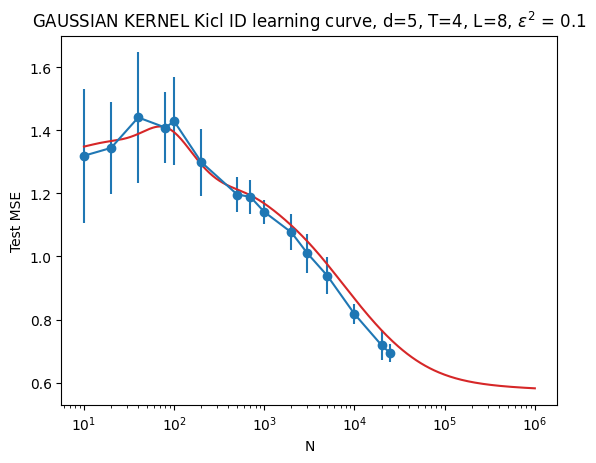

In [ ]:
plt.errorbar(config["ns"], emp_test_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_test_errors, color='tab:red', label="Theory (ID)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN KERNEL Kicl ID learning curve, d={config['dim']}, T={config['T']}, L={config['L']}, $\\epsilon^2$ = {config["sigma_sq"]}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

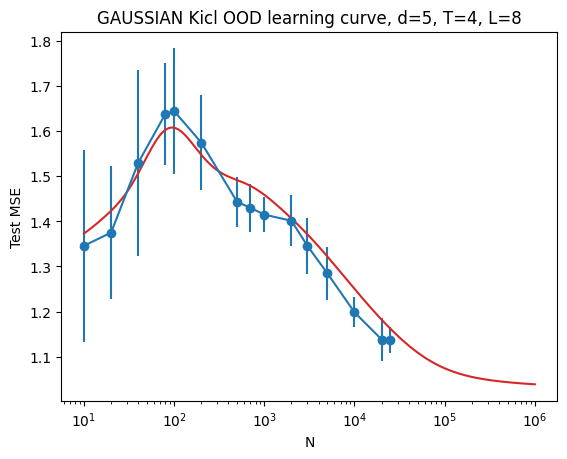

In [ ]:
plt.errorbar(config["ns"], emp_ood_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_ood_errors, color='tab:red', label="Theory (OOD)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN Kicl OOD learning curve, d={config['dim']}, T={config['T']}, L={config['L']}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

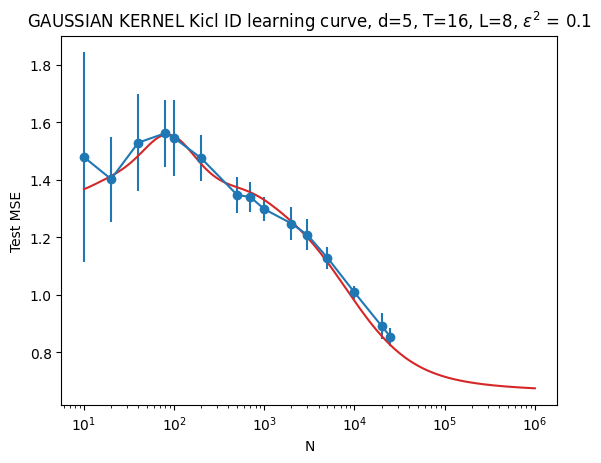

In [ ]:
plt.errorbar(config["ns"], emp_test_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_test_errors, color='tab:red', label="Theory (ID)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN KERNEL Kicl ID learning curve, d={config['dim']}, T={config['T']}, L={config['L']}, $\\epsilon^2$ = {config["sigma_sq"]}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

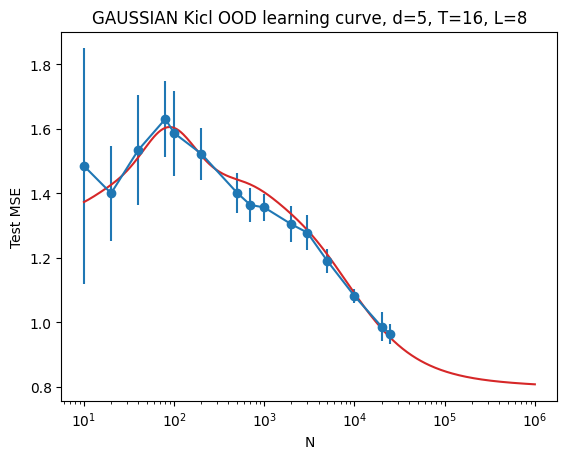

In [ ]:
plt.errorbar(config["ns"], emp_ood_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_ood_errors, color='tab:red', label="Theory (OOD)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN Kicl OOD learning curve, d={config['dim']}, T={config['T']}, L={config['L']}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

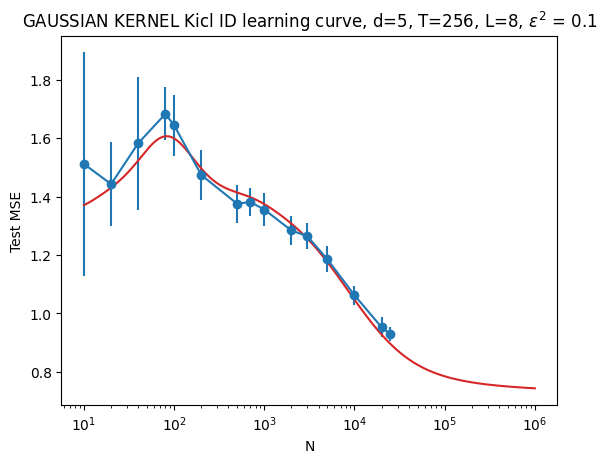

In [ ]:
plt.errorbar(config["ns"], emp_test_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_test_errors, color='tab:red', label="Theory (ID)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN KERNEL Kicl ID learning curve, d={config['dim']}, T={config['T']}, L={config['L']}, $\\epsilon^2$ = {config["sigma_sq"]}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

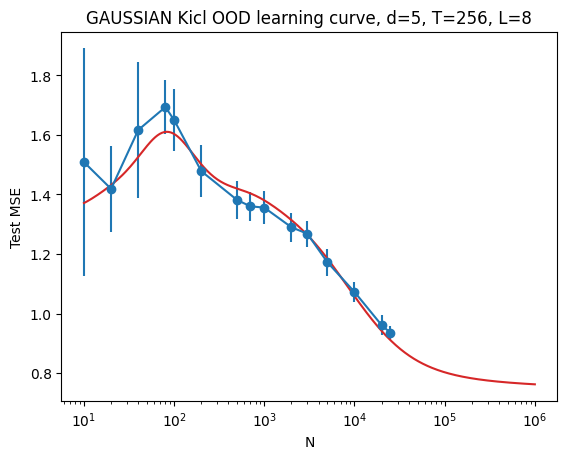

In [ ]:
plt.errorbar(config["ns"], emp_ood_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_ood_errors, color='tab:red', label="Theory (OOD)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN Kicl OOD learning curve, d={config['dim']}, T={config['T']}, L={config['L']}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

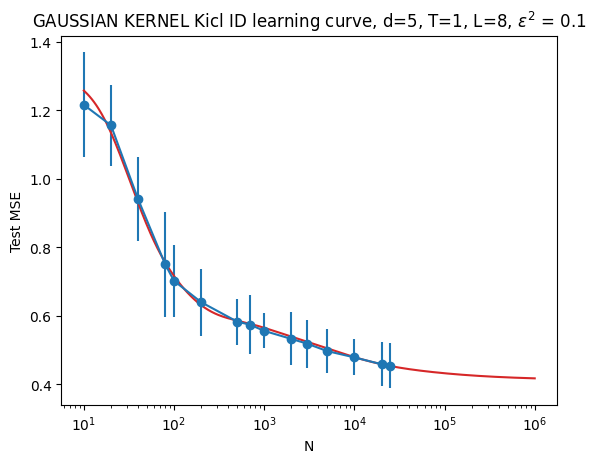

In [ ]:
plt.errorbar(config["ns"], emp_test_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_test_errors, color='tab:red', label="Theory (ID)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN KERNEL Kicl ID learning curve, d={config['dim']}, T={config['T']}, L={config['L']}, $\\epsilon^2$ = {config["sigma_sq"]}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

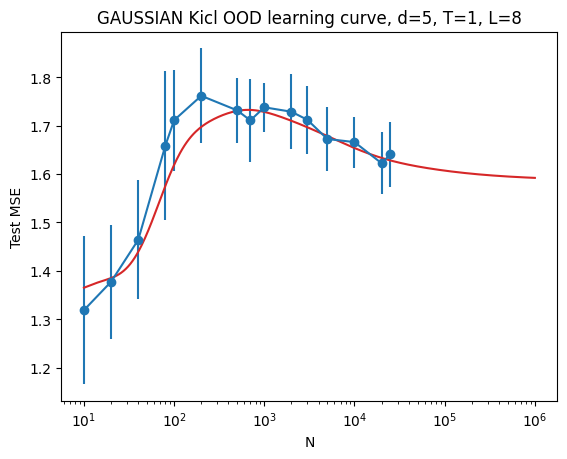

In [ ]:
plt.errorbar(config["ns"], emp_ood_errors.mean(axis=0), yerr=emp_ood_errors.std(axis=0), marker='o', label="Empirical KRR")#/np.sqrt(config["trials"])
plt.plot(th_ns, th_ood_errors, color='tab:red', label="Theory (OOD)")
# plt.plot(th_ns, th_test_errors, color='tab:red', label="Theoretical KRR") #
plt.xlabel("N")
plt.ylabel("Test MSE")
plt.title(f"GAUSSIAN Kicl OOD learning curve, d={config['dim']}, T={config['T']}, L={config['L']}")
plt.xscale("log")
# plt.xlim(100, 30000)
# plt.ylim(0.5, 1)
plt.show()

In [ ]:
savedict = {
    "config": config,
    "results": {
        "emp_ns": config["ns"],
        "th_ns": th_ns,
        "emp_ID_errors": emp_test_errors,
        "th_ID_errors": th_test_errors,
        "emp_OOD_errors": emp_ood_errors,
        "th_OOD_errors": th_ood_errors,
    }
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, 'wb') as f:
    pickle.dump(savedict, f)

In [ ]:
with open(file_path, 'rb') as f:
        loaded_data = pickle.load(f)

In [ ]:
loaded_data

{'config': {'seed': 33,
  'dim': 5,
  'L': 8,
  'distribution': 'pretrain',
  'T': 1,
  'sigma_sq': 0.1,
  'draw_betas': 'normal',
  'beta_sd': 1.0,
  'trials': 20,
  'kernel_class': 'GaussianKernel',
  'kernel_params': {'ridge': 0.01,
   'kernel_width': 3,
   'max_degree': 3,
   'coeffs': [1.0, 0.111, 0.00617283951, 0.000228623685]},
  'n': 14000,
  'ns': [10,
   20,
   40,
   80,
   100,
   200,
   500,
   700,
   1000,
   2000,
   3000,
   5000,
   10000,
   20000,
   25000],
  'min_n': 2,
  'max_n': 30000,
  'memory_safety': 0.2,
  'matrix_factor': 3.0,
  'max_retries': 10,
  'retry_shrink': 0.96,
  'n_test': 2048,
  'expt_dir': 'kernel_ICL/ICLE',
  'base_name': 'eigenstructure_validation_T1',
  'antipodal': False},
 'results': {'emp_ns': [10,
   20,
   40,
   80,
   100,
   200,
   500,
   700,
   1000,
   2000,
   3000,
   5000,
   10000,
   20000,
   25000],
  'th_ns': array([1.00000000e+01, 1.02927477e+01, 1.05940656e+01, 1.09042044e+01,
         1.12234225e+01, 1.15519857e+01,